In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Usted dirige un proyecto de instalaciones cuyo cuadro de prelaciones, duraciones (semanas) y operarios necesarios por actividad se adjunta. La empresa le ha asignado una cuadrilla fija de **8 operarios**, dimensionada justo para el pico de carga del plan de inicios más tempranos. El contrato con el cliente fija la entrega en la semana 16 con una penalización de **5 k€ por semana** de retraso. El proyecto empieza el lunes que viene (semana 1). El viernes recibe estos mensajes.

In [4]:
#| tbl-cap: "Plan del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 2       , 4        ),
    ('B'     , '---'      , 2       , 4        ),
    ('C'     , 'A,B'      , 4       , 2        ),
    ('D'     , 'C'        , 2       , 4        ),
    ('E'     , 'A'        , 2       , 4        ),
    ('F'     , 'D,E'      , 5       , 3        ),
    ('G'     , 'D,E'      , 8       , 1        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,2,4
B,---,2,4
C,"A,B",4,2
D,C,2,4
E,A,2,4
F,"D,E",5,3
G,"D,E",8,1


> **De: Jefa del proyecto Delta**
> Tengo un problema serio: necesito **2 operarios de tu cuadrilla durante las semanas 2 a 4** (ambas incluidas) para un trabajo que no puedo retrasar. Antes de la semana 2 no me sirven. Si no los tengo, mi proyecto se retrasa esas 3 semanas y la penalización de mi cliente es de 8 k€ por semana; cada semana que tarden en llegar a partir de entonces es una semana de retraso para mí. ¿Me los puedes dejar?

> **De: Director de operaciones**
> Lo del proyecto Delta es prioritario para la empresa: es un cliente estratégico y la penalización es alta. Entiendo que tu proyecto también tiene plazo. Dime cuánto te cuesta prestarlos y busquemos la opción más barata para la empresa en conjunto, no para cada proyecto por separado.

> **De: Cliente**
> Les recordamos que la fecha de entrega (semana 16) está ligada a la apertura de nuestras instalaciones y no es negociable. La penalización de 5 k€ por semana se aplicará desde el primer día de retraso.

> **De: Jefe de obra**
> He mirado el plan. En la semana 2 vamos al máximo de gente y la ventana que pide Delta la pisa; si nos quitan 2 operarios ahí, algo se retrasa. En cambio, a partir de la semana 3 tenemos más margen: ahí podríamos prestarlos sin que el plazo se mueva, si a Delta le vale.

> **De: Recursos humanos**
> Podemos subcontratar operarios a 2.5 k€ por operario y semana, pero necesitamos **una semana de preaviso** para tenerlos en obra: como muy pronto, el lunes de la semana 2. Decidid pronto.

Responda a las preguntas siguientes **antes** de decidir. En la penúltima se le pide la decisión y cómo la comunicaría a cada uno de los implicados (jefa del proyecto Delta, director de operaciones, cliente, jefe de obra, recursos humanos).

In [5]:
pregunta_1 = "1. Dibuje el Gantt de inicios más tempranos con las cargas y el diagrama de cargas. ¿En qué semanas se alcanza el máximo de 8 operarios y qué actividades coinciden en ellas? ¿Cuáles son críticas?  "
pregunta_2 = "2. Simule el préstamo de 2 operarios en las semanas 2–4 con un planificador en paralelo (como Wiest-Levy) con un límite de recursos por periodo (8 fuera de la ventana, 6 dentro). ¿Qué actividades esperan, cuánto se alarga el proyecto y cuánto cuesta en penalizaciones?  "
pregunta_3 = "3. Repita la simulación para todas las ventanas posibles de 3 semanas consecutivas. ¿En cuáles se puede prestar sin retrasar el proyecto? Explique el resultado a partir de las cargas y las holguras. ¿Tiene razón el jefe de obra?  "
pregunta_4 = "4. Construya la tabla de opciones (negarse, prestar como se pide, prestar en la ventana del jefe de obra, subcontratar) con el coste de cada una para su proyecto, para el proyecto Delta y para la empresa. ¿Qué opción minimiza el coste de la empresa? ¿Coincide con la que minimiza el de su proyecto?  "
pregunta_5 = "5. Tome una decisión y redacte en tres o cuatro líneas el mensaje de respuesta a cada implicado.  "
pregunta_6 = "6. ¿Qué fallo de organización revela el caso y cómo se evitaría la próxima vez (reparto de recursos entre proyectos, reservas, prioridades)?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el Gantt de inicios más tempranos con las cargas y el diagrama de cargas. ¿En qué semanas se alcanza el máximo de 8 operarios y qué actividades coinciden en ellas? ¿Cuáles son críticas?  

2. Simule el préstamo de 2 operarios en las semanas 2–4 con un planificador en paralelo (como Wiest-Levy) con un límite de recursos por periodo (8 fuera de la ventana, 6 dentro). ¿Qué actividades esperan, cuánto se alarga el proyecto y cuánto cuesta en penalizaciones?  

3. Repita la simulación para todas las ventanas posibles de 3 semanas consecutivas. ¿En cuáles se puede prestar sin retrasar el proyecto? Explique el resultado a partir de las cargas y las holguras. ¿Tiene razón el jefe de obra?  

4. Construya la tabla de opciones (negarse, prestar como se pide, prestar en la ventana del jefe de obra, subcontratar) con el coste de cada una para su proyecto, para el proyecto Delta y para la empresa. ¿Qué opción minimiza el coste de la empresa? ¿Coincide con la que minimiza el de su proyecto?  

5. Tome una decisión y redacte en tres o cuatro líneas el mensaje de respuesta a cada implicado.  

6. ¿Qué fallo de organización revela el caso y cómo se evitaría la próxima vez (reparto de recursos entre proyectos, reservas, prioridades)?  

# Resolución

In [6]:
plazo, penalizacion, penalizacion_delta, coste_sub, q, ventana = 16, 5, 8, 2.5, 2, (2, 4)
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])

El préstamo es un límite de recursos *por periodo*. El algoritmo de asignación de la librería (`asignar`, Wiest-Levy) no interrumpe actividades en curso, así que cuando el límite baja a mitad de una actividad no puede respetarlo; se usa aquí un planificador en paralelo equivalente que sólo deja empezar una actividad si cabe en todas las semanas que va a ocupar.

In [7]:
def programar(limite, L):
    '''Planificador en paralelo con límite por periodo: la semana s admite limite[s] operarios (L si no está en limite).
    Recorre las semanas; en cada una, por orden de holgura total, entra cada actividad disponible (predecesoras terminadas)
    si cabe en el límite de TODAS las semanas que ocuparía; si no, espera. Devuelve los inicios y fines de cada actividad.'''
    D = datos_proyecto['duration'].astype(int); R = datos_proyecto['resources'].astype(int)
    preds = prelaciones.immediate_predecessor
    orden = list(calendario['H_total'].sort_values(kind='stable').index)
    carga, inicio, fin, t = {}, {}, {}, 0
    while len(inicio) < len(D):
        for a in orden:
            if a in inicio or any(p not in fin or fin[p] > t for p in preds[a]):
                continue
            semanas = range(t + 1, t + int(D[a]) + 1)
            if all(carga.get(s, 0) + int(R[a]) <= int(limite.get(s, L)) for s in semanas):
                inicio[a], fin[a] = t, t + int(D[a])
                for s in semanas:
                    carga[s] = carga.get(s, 0) + int(R[a])
        t += 1
    return pd.Series(inicio).reindex(D.index), pd.Series(fin).reindex(D.index)

def proyecto_programado(inicio, fin):
    '''Tabla con actividades de espera 💤 (duración = lo que la actividad espera tras sus predecesoras) para dibujar la programación.'''
    preds = prelaciones.immediate_predecessor
    filas = {}
    for a in datos_proyecto.index:
        ps = sorted(preds[a])
        listo = max([int(fin[p]) for p in ps], default=0)
        if int(inicio[a]) > listo:
            filas['💤' + a] = {'predecessor': ','.join(ps) or '---', 'duration': int(inicio[a]) - listo, 'resources': 0}
            ps = ['💤' + a]
        filas[a] = {'predecessor': ','.join(ps) or '---', 'duration': int(datos_proyecto.loc[a, 'duration']), 'resources': int(datos_proyecto.loc[a, 'resources'])}
    df = pd.DataFrame(filas).T; df.index.name = 'activity'
    df['duration'] = df['duration'].astype(int); df['resources'] = df['resources'].astype(int)
    return df, PredecessorTable.from_dataframe_of_strings(df, activity='activity', predecessor='predecessor').create_project()

def simular_prestamo(ventana, q, L):
    '''Límite L fuera de la ventana y L − q dentro. Devuelve (duración, esperas, dibujo del Gantt con la fila Máximo).'''
    limite = {s: L - q for s in range(ventana[0], ventana[1] + 1)}
    inicio, fin = programar(limite, L)
    df_prog, p_prog = proyecto_programado(inicio, fin)
    T_prog = int(fin.max())
    maximo = pd.DataFrame({s: [limite.get(s, L)] for s in range(1, T_prog + 1)}, index=['Máximo'])
    _, dibujo = p_prog.gantt(df_prog, 'duration', 'resources', total='fila', tikz=True, extra_rows=maximo, params=dict(period_width=1, **GANTT_PARAMS))
    esperas = {a[1:]: int(d) for a, d in df_prog['duration'].items() if a.startswith('💤')}
    return T_prog, esperas, dibujo

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Dibuje el Gantt de inicios más tempranos con las cargas y el diagrama de cargas. ¿En qué semanas se alcanza el máximo de 8 operarios y qué actividades coinciden en ellas? ¿Cuáles son críticas?  

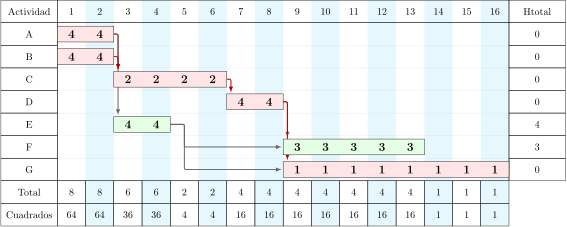

In [9]:
#| fig-cap: "Gantt de inicios más tempranos con los operarios de cada actividad; fila Total, carga por semana"
#| label: fig-ganttCargas
gantt_cargas, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True)
pinta_tikz(dibujo)

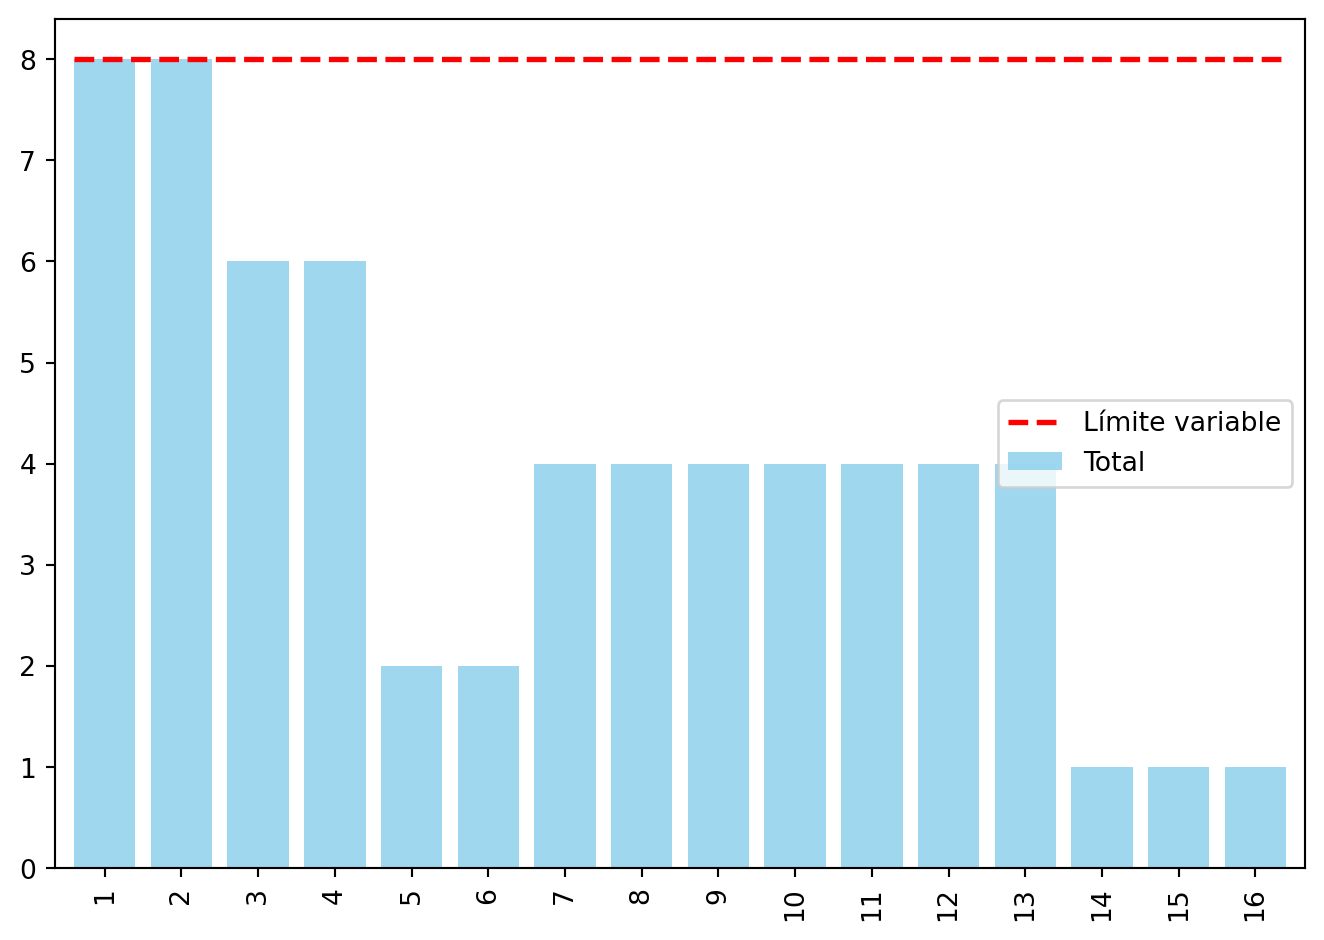

In [10]:
#| fig-cap: "Diagrama de cargas con la cuadrilla disponible"
#| label: fig-cargas
cargas = gantt_cargas.data.loc['Total'].drop('H_total').astype(float)
L = int(cargas.max())
plot_cargas(gantt_df=gantt_cargas, limite_maximo_recursos=[L])

In [11]:
picos = [int(t) for t in cargas.index[cargas == L]]
en_pico = {t: [a for a in datos_proyecto.index if calendario.loc[a, 'inicio_mas_temprano'] < t <= calendario.loc[a, 'fin_mas_temprano']] for t in picos}
criticas = list(calendario.index[calendario['H_total'] == 0])
display(calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'H_total', 'H_libre']])
Markdown(f'''Duración {int(proyecto.duration(datos_proyecto["duration"]))} semanas; críticas: {", ".join(criticas)}. El máximo de {L} operarios se alcanza en las semanas {", ".join(str(t) for t in picos)}; en ellas coinciden {"; ".join(f"semana {t}: {', '.join(acts)}" for t, acts in en_pico.items())}.''')

,inicio_mas_temprano,fin_mas_temprano,H_total,H_libre
activity,,,,
A,0,2,0,0
B,0,2,0,0
C,2,6,0,0
D,6,8,0,0
E,2,4,4,4
F,8,13,3,3
G,8,16,0,0


Duración 16 semanas; críticas: A, B, C, D, G. El máximo de 8 operarios se alcanza en las semanas 1, 2; en ellas coinciden semana 1: A, B; semana 2: A, B.

El plan de inicios más tempranos satura la cuadrilla en las semanas 2. Prestar operarios en una de esas semanas obliga a aplazar alguna actividad; que eso retrase el proyecto depende de si la actividad aplazada tiene holgura suficiente (y de si al aplazarla arrastra a otras hasta agotar la suya).

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Simule el préstamo de 2 operarios en las semanas 2–4 con un planificador en paralelo (como Wiest-Levy) con un límite de recursos por periodo (8 fuera de la ventana, 6 dentro). ¿Qué actividades esperan, cuánto se alarga el proyecto y cuánto cuesta en penalizaciones?  

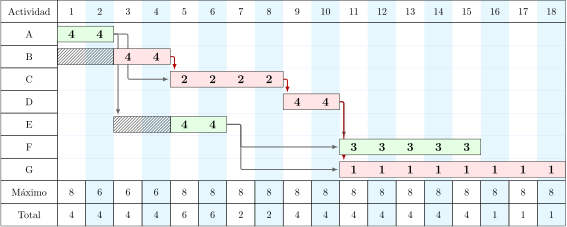

In [13]:
#| fig-cap: "Programación con 6 operarios en las semanas 2–4 y 8 en las demás (fila Máximo); las filas 💤 son las esperas"
#| label: fig-ganttPrestamo
T_prestamo, esperas, dibujo = simular_prestamo(ventana, q, L)
pinta_tikz(dibujo)

In [14]:
Markdown(f'''Con el préstamo el proyecto pasa de {plazo} a **{T_prestamo} semanas** ({T_prestamo - plazo} de retraso, {penalizacion * (T_prestamo - plazo)} k€ de penalización). Esperas introducidas por el algoritmo: {", ".join(f"{a} ({v} sem.)" for a, v in esperas.items()) or "ninguna"}.''')

Con el préstamo el proyecto pasa de 16 a **18 semanas** (2 de retraso, 10 k€ de penalización). Esperas introducidas por el algoritmo: B (2 sem.), E (2 sem.).

El planificador recorre las semanas; en cada una ordena las actividades disponibles por holgura total y deja empezar las que caben en el límite de todas las semanas que ocuparían. En la ventana 2–4 caben 6 operarios y coinciden A, B, C, E: esperan B (2 sem.), E (2 sem.), y el retraso de 2 semanas es lo que de esa espera no absorben las holguras.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. Repita la simulación para todas las ventanas posibles de 3 semanas consecutivas. ¿En cuáles se puede prestar sin retrasar el proyecto? Explique el resultado a partir de las cargas y las holguras. ¿Tiene razón el jefe de obra?  

In [16]:
#| tbl-cap: "Duración del proyecto según la ventana del préstamo"
#| label: tbl-ventanas
w = 3
filas = []
for a in range(1, plazo - w + 2):
    T_a, esperas_a, _ = simular_prestamo((a, a + w - 1), q, L)
    filas.append({'semanas': f'{a}–{a + w - 1}', 'carga antes del préstamo': ', '.join(str(int(cargas[t])) for t in range(a, a + w)),
                  'duración': T_a, 'retraso': T_a - plazo, 'esperas': ', '.join(f'{x} ({v})' for x, v in esperas_a.items()) or '—'})
ventanas = pd.DataFrame(filas).set_index('semanas')
ventanas

,carga antes del préstamo,duración,retraso,esperas
semanas,,,,
1–3,"8, 8, 6",18,2,"B (2), E (1)"
2–4,"8, 6, 6",18,2,"B (2), E (2)"
3–5,"6, 6, 2",16,0,—
4–6,"6, 2, 2",16,0,—
5–7,"2, 2, 4",16,0,—
6–8,"2, 4, 4",16,0,—
7–9,"4, 4, 4",16,0,—
8–10,"4, 4, 4",16,0,—
9–11,"4, 4, 4",16,0,—


Se puede prestar sin mover el plazo en las ventanas 3–5, 4–6, 5–7, 6–8, 7–9, 8–10, 9–11, 10–12, 11–13, 12–14, 13–15, 14–16: o la carga de esas semanas queda por debajo de 6 sin tocar nada, o lo que hay que aplazar tiene holgura de sobra. El jefe de obra tiene razón: desde la semana 3 el préstamo sale gratis en plazo. La ventana que pide Delta (2–4) cuesta 2 semanas porque cae sobre el pico y lo que se aplaza acaba empujando a una actividad crítica.

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. Construya la tabla de opciones (negarse, prestar como se pide, prestar en la ventana del jefe de obra, subcontratar) con el coste de cada una para su proyecto, para el proyecto Delta y para la empresa. ¿Qué opción minimiza el coste de la empresa? ¿Coincide con la que minimiza el de su proyecto?  

In [18]:
#| tbl-cap: "Opciones y su coste (k€) para cada parte"
#| label: tbl-opciones
T_alt, _, _ = simular_prestamo((3, 5), q, L)
espera_delta = 3 - ventana[0]
subcontratar_posible = ventana[0] >= 2     # una semana de preaviso
opciones = pd.DataFrame([
    {'opción': 'negarse', 'mi proyecto': 0, 'proyecto Delta': penalizacion_delta * w, 'detalle': f'Delta se retrasa {w} semanas'},
    {'opción': f'prestar en {ventana[0]}–{ventana[1]}', 'mi proyecto': penalizacion * (T_prestamo - plazo), 'proyecto Delta': 0, 'detalle': f'mi proyecto se retrasa {T_prestamo - plazo}'},
    {'opción': 'prestar en 3–5', 'mi proyecto': penalizacion * (T_alt - plazo), 'proyecto Delta': penalizacion_delta * espera_delta, 'detalle': f'Delta espera {espera_delta} semana' + ('s' if espera_delta != 1 else '')},
    {'opción': f'subcontratar {q} para Delta', 'mi proyecto': 0, 'proyecto Delta': coste_sub * q * w if subcontratar_posible else np.inf,
     'detalle': 'preaviso suficiente' if subcontratar_posible else 'no llegan a tiempo (preaviso de 1 semana)'},
]).set_index('opción')
opciones.insert(2, 'empresa', opciones['mi proyecto'] + opciones['proyecto Delta'])
opciones

,mi proyecto,proyecto Delta,empresa,detalle
opción,,,,
negarse,0,24.0,24.0,Delta se retrasa 3 semanas
prestar en 2–4,10,0.0,10.0,mi proyecto se retrasa 2
prestar en 3–5,0,8.0,8.0,Delta espera 1 semana
subcontratar 2 para Delta,0,15.0,15.0,preaviso suficiente


Para la empresa la opción más barata es **prestar más tarde** (8.0 k€); subcontratar 2 operarios para Delta cuesta 15.0 k€ y llega a tiempo (la ventana empieza en la semana 2, hay una semana de preaviso). Para mi proyecto lo mejor es negarse o prestar en la ventana del jefe de obra (coste cero), pero la primera carga a Delta con 24 k€ y la segunda con 8 k€ de espera. El director de operaciones pide la columna «empresa»: ahí está el conflicto entre la optimización local (cada jefe de proyecto defiende su plazo) y la global.

## Apartado 5

In [19]:
display(Markdown(pregunta_5))

5. Tome una decisión y redacte en tres o cuatro líneas el mensaje de respuesta a cada implicado.  

Una decisión defendible: prestar los 2 operarios desde la semana 3 (gratis para mi plazo) y proponer a Delta que absorba las 1 semanas de espera, o que pida a RR. HH. la subcontratación para cubrir esas semanas si le sale más barato. Mensajes:

- *Jefa de Delta:* «En 2–4 prestar 2 operarios me cuesta 2 semanas de plazo (10 k€). Te los doy sin coste desde la semana 3: esperar 1 semana te cuesta 8 k€, y sigue siendo lo más barato para la empresa.»
- *Director de operaciones:* «Adjunto la tabla con el coste de cada opción para los dos proyectos y para la empresa; la más barata en conjunto es prestar más tarde (8.0 k€). Si decides otra, pido que la penalización resultante se registre como decisión de empresa.»
- *Cliente:* «Mantenemos la entrega en la semana 16.»
- *Jefe de obra:* «Tenías razón con la ventana 3–5; va en la propuesta como alternativa. Prepara el plan de personal con los dos escenarios.»
- *RR. HH.:* «Por ahora no hace falta subcontratar; os aviso si cambia.»

## Apartado 6

In [20]:
display(Markdown(pregunta_6))

6. ¿Qué fallo de organización revela el caso y cómo se evitaría la próxima vez (reparto de recursos entre proyectos, reservas, prioridades)?  

El fallo no es de cálculo sino de organización: dos proyectos comparten un recurso sin que nadie mire el perfil de carga *conjunto*. Lo que lo evita: un diagrama de cargas de la cartera (suma de los proyectos) revisado cada semana por el director de operaciones; reglas explícitas de prioridad entre proyectos antes de que surja el conflicto (no durante); una reserva de capacidad o un acuerdo marco de subcontratación con preaviso corto; y planes nivelados, no de inicios más tempranos, que rebajan los picos y dejan margen para prestar. Y, por supuesto, que la petición llegue con más de un fin de semana de antelación.